# 09 · RT-DETR with a longer training budget

Notebook 06 gave RT-DETR-L (300 queries) one hour on the T4: that was only **3 epochs**, and val mAP was still rising at the end
(0.268 → 0.264 → 0.290 on Ultralytics' val). It was already the best model (official val mAP 0.290, public LB 0.339),
so the model had not converged within the budget. Here the same configuration is trained for **5 hours**; nothing else changes
(same frames, 1280 px, batch 4, optimiser, augmentation, seed), so the difference is the effect of the training length alone.
The cosine schedule is fitted by Ultralytics to the time budget, and mosaic is switched off for the last 2 epochs.

**Run:** Kaggle (GPU T4, Internet ON, inputs: competition + notebook 01 output; notebook 06 output for the curve comparison). About 6 h.

In [1]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Kaggle | outputs -> /kaggle/working


In [2]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.isfinite(d).all(1) & (d[:, 4] > 0) & (d[:, 5] > 0)]           # NaN / empty boxes make the file invalid
        d = d[(d[:, 0] >= 0) & (d[:, 0] < len(CLASSES))]          # e.g. RetinaNet's sigmoid head can output the unused label 0
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [3]:
subprocess.run("pip install -q ultralytics", shell=True, check=True)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, random, time
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import ultralytics
from ultralytics import RTDETR
import vd_utils as vd

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = vd.find_data_root(INPUT)
LOCAL = Path("/content/vd_yolo") if IN_COLAB else WORK / "vd_yolo"
hits = sorted(INPUT.glob("**/vd_yolo/data.yaml")) + sorted(LOCAL.parent.glob("vd_yolo/data.yaml"))
YOLO_DIR = hits[0].parent if hits else vd.build_yolo(ROOT, LOCAL, step=4)
DATA_YAML = WORK / "data.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(vd.CLASSES))}\n")
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def find_file(rel):
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("yolo dataset:", YOLO_DIR)

yolo dataset: /kaggle/input/notebooks/yarema1234/notebook0f34d49e70/vd_yolo


## 1. Training: RT-DETR-L, 300 queries, 5 h instead of 1 h

In [4]:
NAME, TIME_H = "rtdetr_q300_5h", 5.0
yaml = WORK / "rtdetr-l-q300.yaml"                                            # same model file as notebook 06
yaml.write_text((Path(ultralytics.__file__).parent / "cfg/models/rt-detr/rtdetr-l.yaml").read_text()
                .replace("RTDETRDecoder, [nc]]", "RTDETRDecoder, [nc, 256, 300]]"))
CFG = dict(imgsz=1280, epochs=100, time=TIME_H, batch=4, cos_lr=True, close_mosaic=2, seed=SEED, workers=4 if not IN_COLAB else 2,
           device=DEVICE, project=str(WORK / "detr_runs"), exist_ok=True, plots=True)
best = find_file(f"detr_runs/{NAME}/weights/best.pt")
train_min = np.nan
if best is None:
    t0 = time.time()
    RTDETR(str(yaml)).load("rtdetr-l.pt").train(data=str(DATA_YAML), name=NAME, **CFG)   # COCO-pretrained weights
    train_min = (time.time() - t0) / 60
    best = WORK / "detr_runs" / NAME / "weights" / "best.pt"
    gc.collect(); torch.cuda.empty_cache()
print("weights:", best, "| train min:", round(train_min, 1))

Using 6072 train, 2846 val images for fraction=1.0 at imgsz=1280
                   all       2846     112903      0.576      0.507      0.514      0.268
                   all       2846     112903      0.598      0.539      0.517      0.265
                   all       2846     112903      0.578      0.522       0.51       0.26
                   all       2846     112903      0.658        0.5       0.52      0.273
                   all       2846     112903      0.617       0.51      0.515      0.261
                   all       2846     112903       0.61      0.503       0.52      0.271
                   all       2846     112903      0.617      0.507      0.506       0.26
                   all       2846     112903      0.575      0.489      0.477      0.242
                   all       2846     112903      0.622      0.498      0.496      0.252
                   all       2846     112903      0.665      0.502      0.507      0.263
                   all       2846     112903 

## 2. Did it converge? Val mAP over training time, 1 h vs 5 h
Ultralytics' per-epoch validation (masked val frames). The 1 h curve comes from notebook 06 (attach its output).

rtdetr_q300_5h: 12 epochs, best epoch 4, best mAP 0.273
rtdetr_q300 (1 h, nb06): 3 epochs, best epoch 3, best mAP 0.290


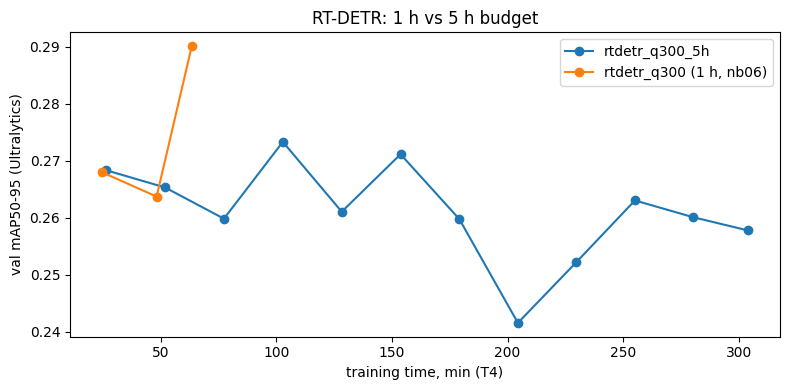

In [5]:
curves = {NAME: best.parent.parent / "results.csv", "rtdetr_q300 (1 h, nb06)": find_file("detr_runs/rtdetr_q300/results.csv")}
fig, ax = plt.subplots(figsize=(8, 4))
for name, f in curves.items():
    if f is None or not Path(f).exists(): continue
    c = pd.read_csv(f); c.columns = c.columns.str.strip()
    ax.plot(c["time"] / 60, c["metrics/mAP50-95(B)"], marker="o", label=name)
    print(f"{name}: {len(c)} epochs, best epoch {int(c['metrics/mAP50-95(B)'].idxmax()) + 1}, best mAP {c['metrics/mAP50-95(B)'].max():.3f}")
ax.set_xlabel("training time, min (T4)"); ax.set_ylabel("val mAP50-95 (Ultralytics)"); ax.legend(); ax.set_title("RT-DETR: 1 h vs 5 h budget")
plt.tight_layout(); plt.savefig(WORK / "curves_detr_long.png", dpi=120); plt.show()

## 3. Official validation, compared with the 1 h run

In [6]:
def predict(model, paths, imgsz, conf=0.001, bs=4):
    # {path: array N x 6 [cls, score, x, y, w, h]} in original pixels; small explicit chunks avoid GPU OOM
    out, t0 = {}, time.time()
    for k in range(0, len(paths), bs):
        for r in model.predict(paths[k:k + bs], imgsz=imgsz, conf=conf, max_det=500, verbose=False):
            b = r.boxes; xyxy = b.xyxy.cpu().numpy()
            out[r.path] = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]]
    return out, (time.time() - t0) / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

model = RTDETR(best)
vp, ms = predict(model, val_imgs["path"].tolist(), imgsz=1280)
R = pd.DataFrame({NAME: {**vd.coco_eval(VAL_GT, to_coco(vp, val_imgs)), "ms / image (incl. disk)": ms, "train min": train_min}}).T
prev = find_file("results_detr.csv")                                            # notebook 06 output, if attached
if prev is not None:
    R = pd.concat([pd.read_csv(prev, index_col=0).loc[["rtdetr_q300"]].rename(index={"rtdetr_q300": "rtdetr_q300 (1 h)"}), R])
R.to_csv(WORK / "results_detr_long.csv")
display(R[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms / image (incl. disk)", "train min"]].astype(float).round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.astype(float).round(3))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms / image (incl. disk),train min
rtdetr_q300 (1 h),0.2904,0.5540,0.2647,0.1584,0.2517,0.4584,263.7565,75.8700
rtdetr_q300_5h,0.2730,0.5148,0.2574,0.1501,0.2356,0.4663,283.8858,314.6488


,rtdetr_q300 (1 h),rtdetr_q300_5h
AP_person,0.309,0.291
AP_bicycle,0.256,0.232
AP_car,0.457,0.438
AP_van,0.304,0.298
AP_truck,0.316,0.277
AP_tricycle,0.267,0.245
AP_bus,0.278,0.265
AP_motor,0.140,0.139


## 4. Test submission (RT-DETR 5 h alone)

In [7]:
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist(), imgsz=1280)
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_detr_5h.csv")
print("written submission_detr_5h.csv")

written submission_detr_5h.csv
